Title: Heart Health Information Assistant Using NLP and Machine Learning

In [ ]:
!pip install nltk scikit-learn pandas matplotlib seaborn

import nltk
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("Libraries imported successfully!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Libraries imported successfully!


In [ ]:
data = {

"symptoms": [
    "What are common symptoms of heart disease?",
    "Why do I feel chest discomfort?",
    "What causes shortness of breath?",
    "Why does my heart beat rapidly?",
    "What are signs of poor heart health?",
    "Can heart disease cause fatigue?",
    "Why do I feel dizzy sometimes?",
    "What are symptoms of irregular heartbeat?",
    "Can heart problems cause weakness?",
    "What are warning signs of heart problems?"
],

"risk_factors": [
    "What causes heart disease?",
    "Does smoking increase heart disease risk?",
    "Can obesity affect heart health?",
    "Does high cholesterol cause heart problems?",
    "Can diabetes increase heart disease risk?",
    "Does family history affect heart health?",
    "Can stress affect the heart?",
    "Does high blood pressure damage the heart?",
    "Can alcohol affect heart health?",
    "Does lack of exercise increase heart risk?"
],

"prevention": [
    "How can I prevent heart disease?",
    "How can I keep my heart healthy?",
    "What habits improve heart health?",
    "How can I reduce heart disease risk?",
    "How can I control my blood pressure?",
    "How can I lower cholesterol naturally?",
    "How important is regular health screening?",
    "How can I protect my heart?",
    "What lifestyle changes prevent heart disease?",
    "How can I improve cardiovascular health?"
],

"diet": [
    "What foods are good for the heart?",
    "Should I reduce salt intake?",
    "Are fruits good for heart health?",
    "What is a heart healthy diet?",
    "Is oily food bad for the heart?",
    "Are vegetables beneficial for the heart?",
    "Should I avoid processed foods?",
    "Are nuts good for cardiovascular health?",
    "What foods help control cholesterol?",
    "How much salt should I consume?"
],

"exercise": [
    "Which exercise is good for the heart?",
    "Is walking beneficial for heart health?",
    "How often should I exercise?",
    "Can cycling improve heart health?",
    "Does jogging strengthen the heart?",
    "Is yoga helpful for heart health?",
    "How does physical activity help the heart?",
    "Can regular exercise reduce blood pressure?",
    "How much walking is recommended?",
    "Is swimming good for cardiovascular health?"
],

"diagnosis": [
    "What is an ECG test?",
    "How is heart disease diagnosed?",
    "What is an echocardiogram?",
    "Why do doctors recommend a stress test?",
    "What is a cholesterol test?",
    "How is blood pressure measured?",
    "What does an ECG report show?",
    "What is an angiography test?",
    "How do doctors check heart function?",
    "What tests detect heart problems?"
],

"medication": [
    "Why are heart medicines prescribed?",
    "What are blood pressure medicines?",
    "What is the purpose of statins?",
    "Can medicines control cholesterol?",
    "Why do doctors prescribe aspirin?",
    "What are common heart medications?",
    "How do blood pressure medicines work?",
    "Why is medication important for heart patients?",
    "Should I stop taking my heart medicine?",
    "Can I change my heart medication dose?"
],

"emergency": [
    "What should I do during a heart attack?",
    "What are heart attack warning signs?",
    "Someone has severe chest pain what should I do?",
    "What should I do if someone collapses?",
    "Can sudden chest pressure be an emergency?",
    "What should I do during severe breathing difficulty?",
    "How to respond to suspected heart attack?",
    "What should I do if someone becomes unconscious?",
    "Is sudden severe chest pain dangerous?",
    "How do I get emergency heart assistance?"
]

}

# Convert dictionary into dataframe

texts = []
labels = []

for intent, queries in data.items():
    for query in queries:
        texts.append(query)
        labels.append(intent)

df = pd.DataFrame({
    "query": texts,
    "intent": labels
})

print(df.head())
print("\nTotal queries:", len(df))
print("\nIntent distribution:")
print(df['intent'].value_counts())

                                        query    intent
0  What are common symptoms of heart disease?  symptoms
1             Why do I feel chest discomfort?  symptoms
2            What causes shortness of breath?  symptoms
3             Why does my heart beat rapidly?  symptoms
4        What are signs of poor heart health?  symptoms

Total queries: 80

Intent distribution:
intent
symptoms        10
risk_factors    10
prevention      10
diet            10
exercise        10
diagnosis       10
medication      10
emergency       10
Name: count, dtype: int64


In [ ]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):

    text = text.lower()

    text = re.sub(r'[^a-z\s]', '', text)

    tokens = word_tokenize(text)

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    return " ".join(tokens)

df['cleaned_query'] = df['query'].apply(preprocess_text)

print(df[['query', 'cleaned_query']].head(10))

                                        query                 cleaned_query
0  What are common symptoms of heart disease?  common symptom heart disease
1             Why do I feel chest discomfort?         feel chest discomfort
2            What causes shortness of breath?        cause shortness breath
3             Why does my heart beat rapidly?            heart beat rapidly
4        What are signs of poor heart health?        sign poor heart health
5            Can heart disease cause fatigue?   heart disease cause fatigue
6              Why do I feel dizzy sometimes?          feel dizzy sometimes
7   What are symptoms of irregular heartbeat?   symptom irregular heartbeat
8          Can heart problems cause weakness?  heart problem cause weakness
9   What are warning signs of heart problems?    warning sign heart problem


In [ ]:
vectorizer = TfidfVectorizer()

X = vectorizer.fit_transform(df['cleaned_query'])

y = df['intent']

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (80, 124)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model training completed!")

Model training completed!


Accuracy: 0.65
Precision: 0.8452380952380952
Recall: 0.65
F1 Score: 0.6761111111111111

Classification Report:
              precision    recall  f1-score   support

   diagnosis       0.50      0.50      0.50         2
        diet       0.67      1.00      0.80         2
   emergency       1.00      0.67      0.80         3
    exercise       1.00      0.33      0.50         3
  medication       1.00      0.67      0.80         3
  prevention       0.29      1.00      0.44         2
risk_factors       1.00      0.67      0.80         3
    symptoms       1.00      0.50      0.67         2

    accuracy                           0.65        20
   macro avg       0.81      0.67      0.66        20
weighted avg       0.85      0.65      0.68        20



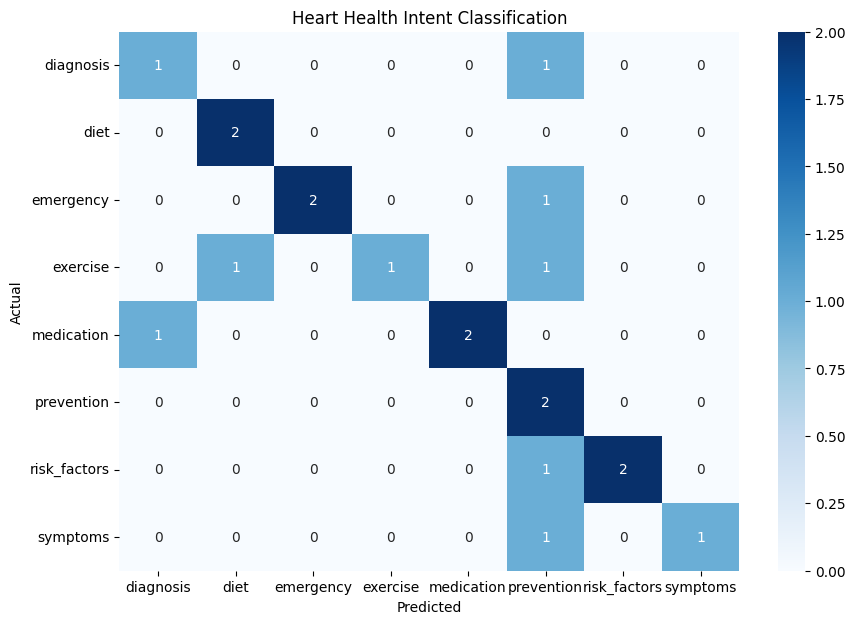

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average='weighted', zero_division=0
)

recall = recall_score(
    y_test, y_pred, average='weighted', zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average='weighted', zero_division=0
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(
    y_test, y_pred, labels=model.classes_
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=model.classes_,
    yticklabels=model.classes_,
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Heart Health Intent Classification")
plt.show()

In [ ]:
knowledge_base = {

"symptoms": """
Common heart-related symptoms may include chest discomfort,
shortness of breath, fatigue, dizziness and irregular heartbeat.

Symptoms can have many causes. Consult a healthcare professional
for proper evaluation.
""",

"risk_factors": """
Risk factors for heart disease include smoking, high blood pressure,
high cholesterol, diabetes, obesity, physical inactivity and family history.

Some risk factors can be managed through lifestyle changes
and medical care.
""",

"prevention": """
Heart disease risk can be reduced through regular physical activity,
a balanced diet, avoiding smoking, maintaining a healthy weight,
managing blood pressure and controlling cholesterol.
""",

"diet": """
A heart-healthy diet generally includes fruits, vegetables,
whole grains, nuts and appropriate sources of protein.

Limit excess salt, saturated fats and highly processed foods.
""",

"exercise": """
Regular physical activity supports cardiovascular health.

Walking, cycling and swimming are examples of activities.
Choose exercise according to your health condition and
consult a doctor before starting if you have health concerns.
""",

"diagnosis": """
Doctors may use ECG, echocardiography, blood tests,
stress tests and other investigations to assess heart health.

The appropriate test depends on symptoms and medical history.
""",

"medication": """
Heart-related medicines may include blood pressure medicines,
cholesterol-lowering medicines and other prescribed treatments.

Always follow your doctor's instructions.
Never stop or change prescribed medication without consulting
your healthcare professional.
""",

"emergency": """
A suspected heart attack is a medical emergency.

Call India's emergency number 112 or seek emergency medical
assistance immediately.

Do not delay treatment while trying to use this assistant.
"""
}

print("Heart Health Knowledge Base Created!")

Heart Health Knowledge Base Created!


In [ ]:
# Heart-related keywords
heart_keywords = [
    "heart", "cardiac", "cardiovascular", "chest",
    "ecg", "cholesterol", "blood pressure", "pulse",
    "heartbeat", "blood vessel", "blood flow",
    "heart attack", "angiography", "echocardiogram",
    "arrhythmia", "statin", "hypertension",
    "cardiology", "cardiologist", "coronary"
]

# Emergency keywords
emergency_keywords = [
    "heart attack",
    "severe chest pain",
    "chest pressure",
    "crushing chest",
    "unconscious",
    "collapsed",
    "cannot breathe",
    "severe breathing difficulty"
]

def assistant_response(user_query):

    # Rule 1: Empty query
    if not user_query.strip():
        return "Please enter a question related to heart health."

    query = user_query.lower()

    # Rule 2: Emergency escalation
    if any(word in query for word in emergency_keywords):

        return knowledge_base["emergency"]

    # Rule 3: Unsupported query
    if not any(word in query for word in heart_keywords):

        return (
            "Sorry, I can only answer questions related to "
            "heart health. Please ask a heart-health-related question."
        )

    # Preprocess query
    cleaned = preprocess_text(user_query)

    # Convert into TF-IDF features
    vector = vectorizer.transform([cleaned])

    # Rule 4: Low-confidence handling
    if vector.nnz == 0:
        return (
            "I could not understand your question clearly. "
            "Please rephrase it using heart-health-related terms."
        )

    probabilities = model.predict_proba(vector)[0]

    confidence = max(probabilities)

    predicted_intent = model.predict(vector)[0]

    if confidence < 0.25:

        return (
            "I am not confident about understanding this question. "
            "Please rephrase your query or consult a healthcare professional."
        )

    # Rule 5: Medication safety
    if predicted_intent == "medication":

        return knowledge_base["medication"]

    # Rule 6: Retrieve response from knowledge base
    response = knowledge_base.get(predicted_intent)

    if response is None:

        return "Sorry, relevant information is unavailable."

    return (
        f"Detected Intent: {predicted_intent}\n"
        f"Confidence: {confidence:.2f}\n\n"
        f"Assistant Response:\n{response}"
    )


print("Reasoning rules implemented successfully!")

Reasoning rules implemented successfully!


In [ ]:
print("     HEART HEALTH ASSISTANT")

print("Ask me questions about heart health.")
print("Type 'exit' to stop the assistant.")

while True:

    user_input = input("\nYou: ")

    if user_input.lower() == "exit":
        print("Assistant: Thank you for using Heart Health Assistant!")
        break

    response = assistant_response(user_input)

    print("\nAssistant:", response)

     HEART HEALTH ASSISTANT
Ask me questions about heart health.
Type 'exit' to stop the assistant.

You: What foods are good for the heart?

Assistant: Detected Intent: diet
Confidence: 0.42

Assistant Response:

A heart-healthy diet generally includes fruits, vegetables,
whole grains, nuts and appropriate sources of protein.

Limit excess salt, saturated fats and highly processed foods.


You: What is an ECG test?

Assistant: Detected Intent: diagnosis
Confidence: 0.43

Assistant Response:

Doctors may use ECG, echocardiography, blood tests,
stress tests and other investigations to assess heart health.

The appropriate test depends on symptoms and medical history.


You: exit
Assistant: Thank you for using Heart Health Assistant!
